# Import Libs

In [2]:
import json
import pandas as pd
import matplotlib.pyplot as plt

# Load Data

In [3]:
BASE_DIR = "../gis-analytics-assessment-materials"

with open(f"{BASE_DIR}/products.json", "r", encoding="utf-8") as file:
    products = json.load(file)


analytics = pd.read_csv(
    f"{BASE_DIR}/analytics.csv",
    header=None,
    skiprows=1,
    # names=analytics_columns,
)

products_df = pd.DataFrame(products)

# Data Prepration 

In [4]:
print(f"Number of products: {len(products_df)}")
print(f"Number of columns: {len(products_df.columns)}")
print(f"Data columns: {products_df.columns.tolist()}")

Number of products: 48
Number of columns: 13
Data columns: ['id', 'name', 'category', 'price_gbp', 'colours', 'fabric', 'fit', 'sizes', 'occasions', 'made_to_order', 'lead_time_days', 'description', 'in_stock']


In [5]:
print(products_df.head())

        id         name category  price_gbp               colours  fabric  \
0  VLM-001  Livia dress    dress        590              [pewter]  jersey   
1  VLM-002   Vela dress    dress        340     [ivory, midnight]  velvet   
2  VLM-003  Isola dress    dress        310  [champagne, emerald]  jersey   
3  VLM-004  Livia dress    dress        410     [black, sapphire]  jersey   
4  VLM-005   Vela dress    dress        420    [emerald, oxblood]  jersey   

          fit                                            sizes  \
0     relaxed  [UK 6, UK 8, UK 10, UK 12, UK 14, UK 16, UK 18]   
1     relaxed  [UK 6, UK 8, UK 10, UK 12, UK 14, UK 16, UK 18]   
2      column  [UK 6, UK 8, UK 10, UK 12, UK 14, UK 16, UK 18]   
3     relaxed  [UK 6, UK 8, UK 10, UK 12, UK 14, UK 16, UK 18]   
4  structured  [UK 6, UK 8, UK 10, UK 12, UK 14, UK 16, UK 18]   

                     occasions  made_to_order  lead_time_days  \
0  [christmas party, cocktail]           True              18   
1        [

In [6]:
products_df["price_gbp"] = pd.to_numeric(products_df["price_gbp"])
products_df["lead_time_days"] = pd.to_numeric(products_df["lead_time_days"])
    
print("\nPRICE SUMMARY")
print(products_df["price_gbp"].describe())

print("\nPRODUCTS BY CATEGORY")
print(products_df["category"].value_counts())

print("\nPRODUCTION STATUS")
print(products_df["made_to_order"].value_counts())


PRICE SUMMARY
count     48.000000
mean     393.333333
std      144.521711
min       90.000000
25%      295.000000
50%      380.000000
75%      492.500000
max      680.000000
Name: price_gbp, dtype: float64

PRODUCTS BY CATEGORY
category
dress        26
jumpsuit      6
top           6
skirt         5
outerwear     3
accessory     2
Name: count, dtype: int64

PRODUCTION STATUS
made_to_order
True     38
False    10
Name: count, dtype: int64


# Chart Setup

In [7]:
plt.rcParams["figure.figsize"] = (9, 5)

# Price Distro Chart

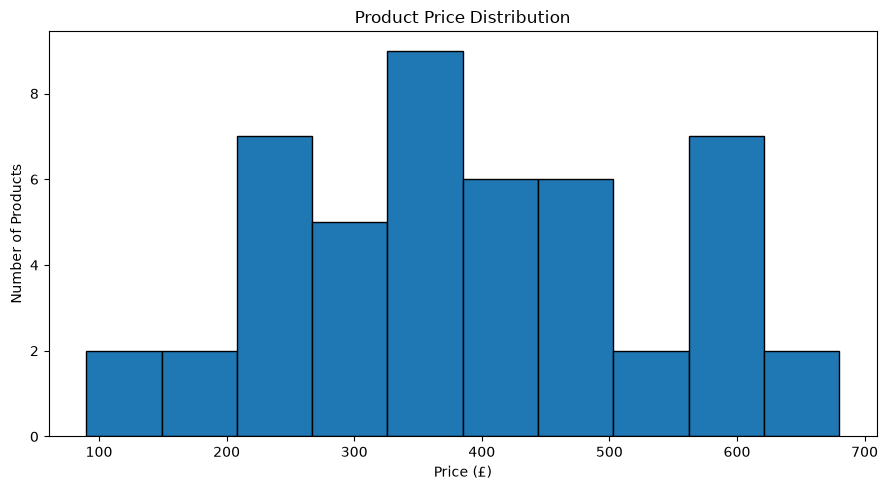

In [8]:
plt.figure()
plt.hist(products_df["price_gbp"], bins=10, edgecolor="black")
plt.title("Product Price Distribution")
plt.xlabel("Price (£)")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.show()

As in the brand.md said - Prices from £60 to £690; a typical order is about £335.

# Products and Category

## Cat numbers

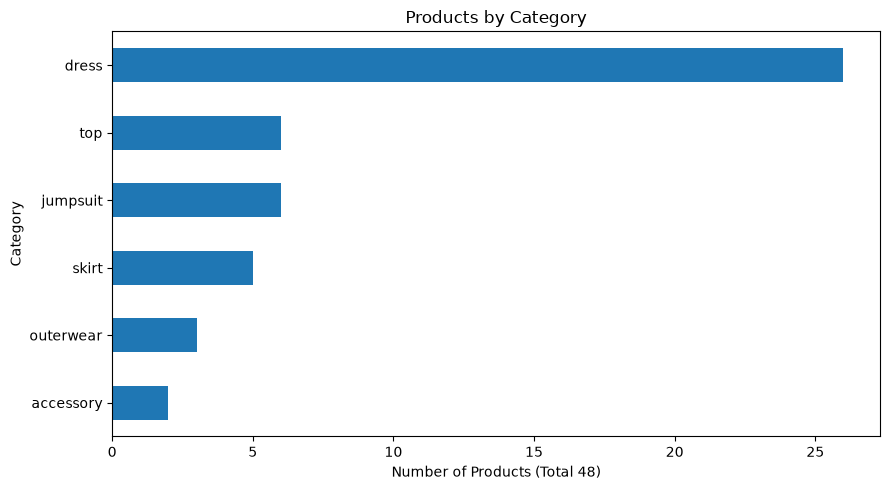

In [9]:
category_counts = products_df["category"].value_counts().sort_values()

plt.figure()
category_counts.plot(kind="barh")
plt.title("Products by Category")
plt.xlabel("Number of Products (Total {})".format(len(products_df)))
plt.ylabel("Category")
plt.tight_layout()
plt.show()

as in the brand.md said 
- 48 pieces: dresses, jumpsuits, tops, skirts, outerwear and two accessories (`products.json`).
- Most pieces are made to order in the London studio, in 14 to 21 days. Accessories ship from stock.

## Avg Price in each cat

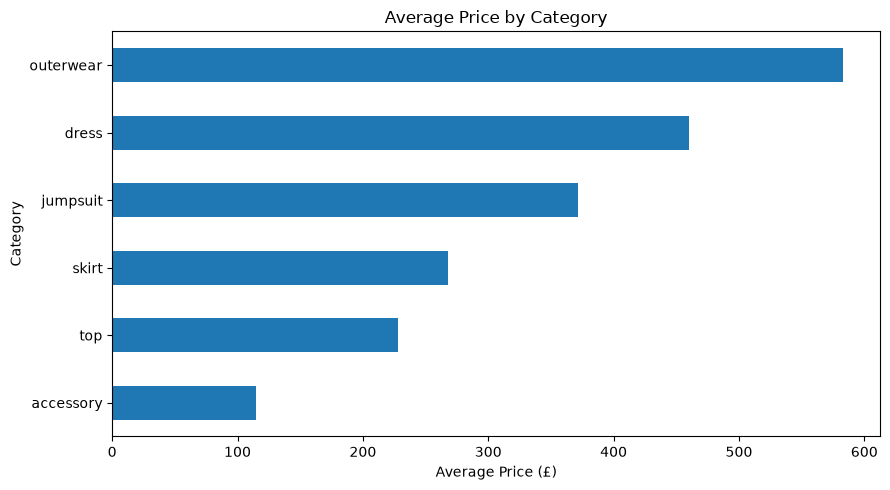

In [10]:
average_prices = (
    products_df.groupby("category")["price_gbp"]
    .mean()
    .sort_values()
)

plt.figure()
average_prices.plot(kind="barh")
plt.title("Average Price by Category")
plt.xlabel("Average Price (£)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

# Order (Made to order)

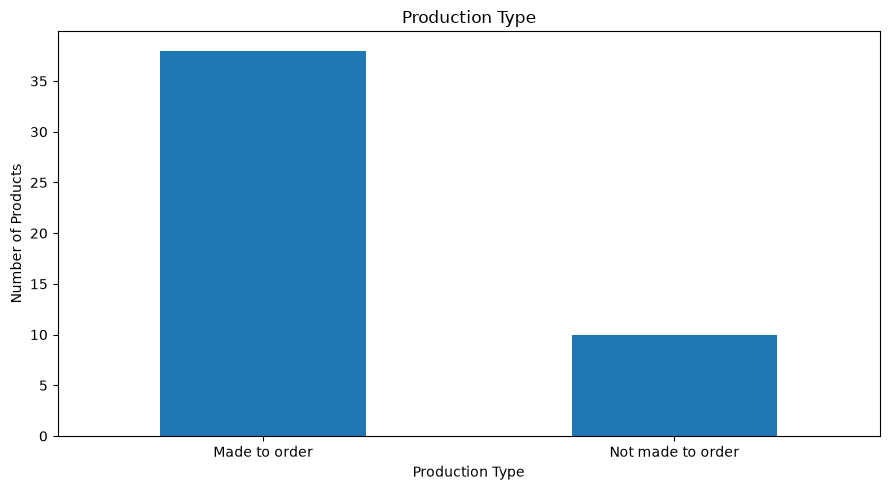

In [11]:
production_counts = pd.Series({
    "Made to order": products_df["made_to_order"].sum(),
    "Not made to order": (~products_df["made_to_order"]).sum()
})

plt.figure()
production_counts.plot(kind="bar")
plt.title("Production Type")
plt.xlabel("Production Type")
plt.ylabel("Number of Products")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

From the above charts we can decide
- we should focus on () category since people like it more than others and pruches it more
- we should focus on () category because people mostly purches at that price
- we should focus on () ocasions since people liked them more

# Lead-time distribution by category

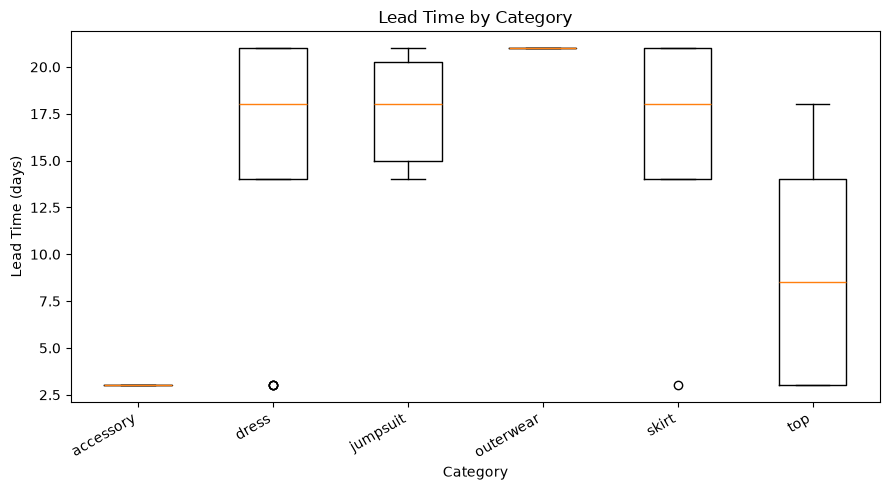

In [12]:
categories = sorted(products_df["category"].unique())

lead_time_data = [
    products_df.loc[products_df["category"] == category, "lead_time_days"].dropna()
    for category in categories
]

plt.figure()
plt.boxplot(lead_time_data, tick_labels=categories)
plt.title("Lead Time by Category")
plt.xlabel("Category")
plt.ylabel("Lead Time (days)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# Number of products associated with each occasion

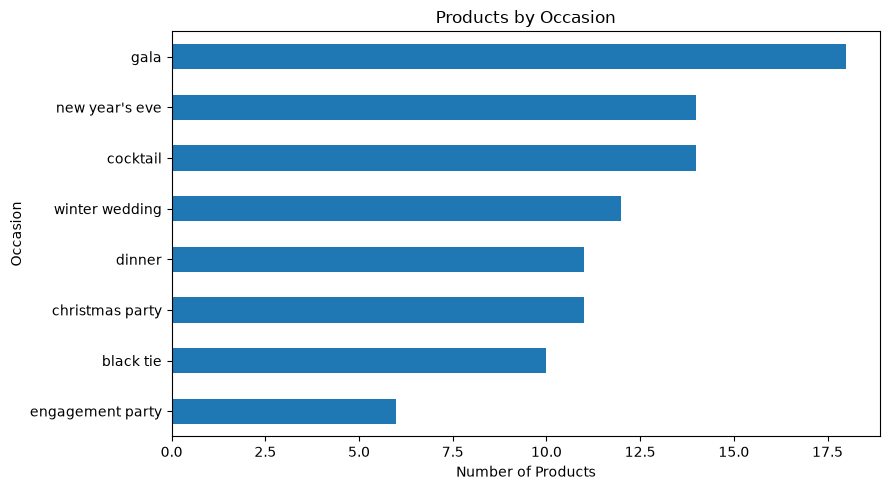

In [13]:
occasion_counts = (
    products_df["occasions"]
    .explode()
    .dropna()
    .value_counts()
    .sort_values()
)

plt.figure()
occasion_counts.plot(kind="barh")
plt.title("Products by Occasion")
plt.xlabel("Number of Products")
plt.ylabel("Occasion")
plt.tight_layout()
plt.show()


# Product price versus lead time

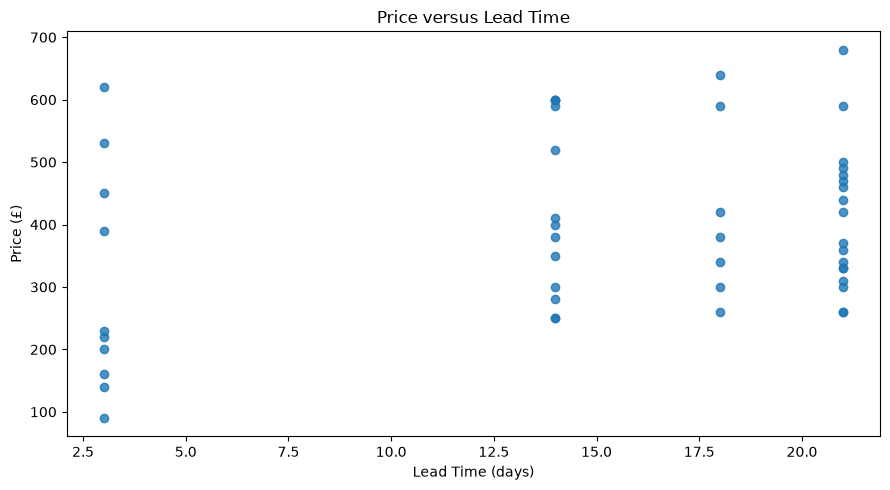

In [14]:
plt.figure()
plt.scatter(
    products_df["lead_time_days"],
    products_df["price_gbp"],
    alpha=0.8
)
plt.title("Price versus Lead Time")
plt.xlabel("Lead Time (days)")
plt.ylabel("Price (£)")
plt.tight_layout()
plt.show()

# Products by stock status

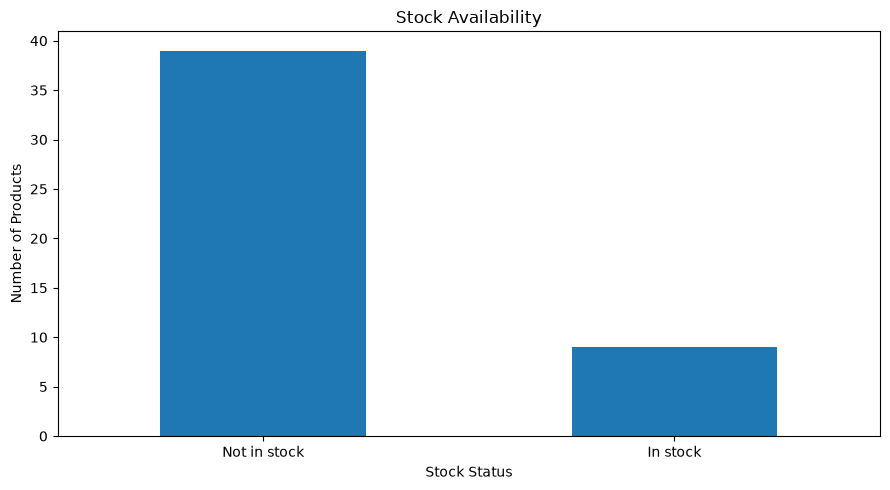

In [15]:
stock_counts = products_df["in_stock"].value_counts().rename({
    True: "In stock",
    False: "Not in stock"
})

plt.figure()
stock_counts.plot(kind="bar")
plt.title("Stock Availability")
plt.xlabel("Stock Status")
plt.ylabel("Number of Products")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Price Distro

/var/folders/2s/0zxclzbn72v7y5kgrldn7w0w0000gn/T/ipykernel_69672/32992542.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


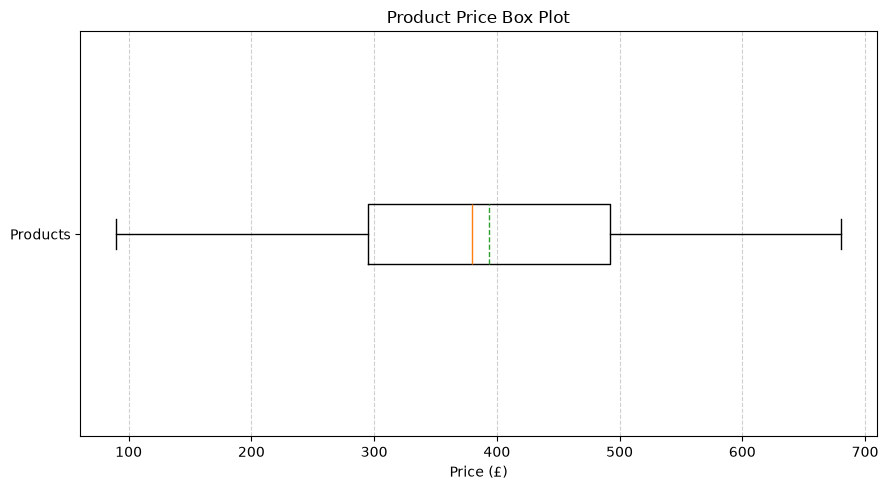

In [16]:
plt.figure()
plt.boxplot(
    products_df["price_gbp"].dropna(),
    vert=False,
    showmeans=True,
    meanline=True
)

plt.title("Product Price Box Plot")
plt.xlabel("Price (£)")
plt.yticks([1], ["Products"])
plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()